# Beat 3: Variantes de ReLU (Deconvnet e Guided Backpropagation)

**Pergunta:** Por que Deconv e Guided parecem melhores?

Este notebook apresenta a diferença nas regras de retropropagação através das ReLUs (Vanilla, Deconvnet e Guided Backpropagation) e mostra a medição de discriminação de classe entre os métodos.

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

import deck
from gradcam import saliency_map_fn
from gradcam.metrics import spearman
from gradcam.models import load_model, preprocess, imagenet_labels, resolve_class
from gradcam.viz import figure_grid, overlay, tensor_to_numpy
from gradcam.models import denormalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
print(f"VGG-16 carregado em {device}")

VGG-16 carregado em cpu


## Comparando os mapas com as 3 regras de ReLU

Calculando lado a lado: Vanilla, Deconv e Guided.

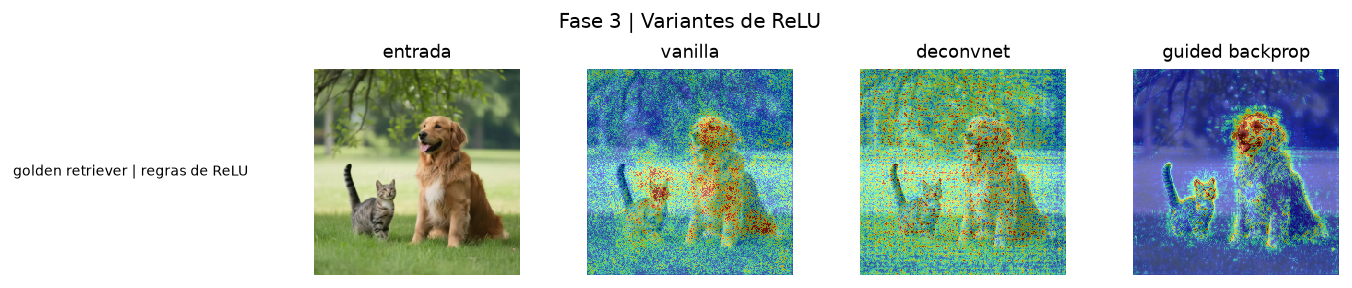

Spearman(vanilla, deconv) = 0.137
Spearman(vanilla, guided) = 0.459


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

class_top1 = int(model(x).argmax(dim=1))
class_alt = resolve_class("tennis ball", labels)

vanilla_fn = saliency_map_fn("vanilla")
deconv_fn = saliency_map_fn("deconv")
guided_fn = saliency_map_fn(
    "guided"
)

v_map = vanilla_fn(model, x, class_top1).detach()
d_map = deconv_fn(model, x, class_top1).detach()
g_map = guided_fn(model, x, class_top1).detach()

DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, v_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
            overlay(image_rgb, d_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
            overlay(image_rgb, g_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ]
    ],
    col_titles=("entrada", "vanilla", "deconvnet", "guided backprop"),
    row_titles=[f"{labels[class_top1]} | regras de ReLU"],
    suptitle="Fase 3 | Variantes de ReLU",
)
plt.show()

rho_vd = spearman(v_map, d_map)
rho_vg = spearman(v_map, g_map)
print(f"Spearman(vanilla, deconv) = {rho_vd:.3f}")
print(f"Spearman(vanilla, guided) = {rho_vg:.3f}")

## Discriminabilidade de Classe (Spearman entre classes diferentes)

Carregando métricas computadas do cache para ilustrar que métodos nítidos podem ter baixa seletividade de classe.

In [3]:
try:
    metrics = deck.result("class_discrimination")
    agg = metrics["aggregate"]
    fig, ax = plt.subplots(figsize=(6, 4), dpi=110)
    methods = list(agg.keys())
    values = [agg[m]["mean"] for m in methods]
    ax.bar(methods, values, color=['gray', 'blue', 'green', 'orange', 'purple'])
    ax.set_ylim(0, 1.1)
    ax.set_title("Discriminação de Classe (Spearman)")
    deck.show(fig)
except Exception as e:
    print(f"Métrica não encontrada ou pendente: {e}")

Métrica não encontrada ou pendente: Métrica não encontrada em results\metrics\class_discrimination.json. Execute o script correspondente primeiro.
